# 01: position, velocity and particle tracking

The lecture demonstration shows how a position measurement also corrects velocity (or slope). E1 applies the same covariance coupling to particle tracking (25 minutes); E3 adapts it to timestamped drone sensors. 

Use **Kernel > Change Kernel > Crazyflie lectures (.venv)** and run setup, then the following cells with Shift+Enter. Results go to `data/<run_id>/`; choose a new run label for a new session.

Continue afterwards with [02 calibration](02_calibration.ipynb), then [03 height and velocity](03_height_velocity.ipynb). Each notebook runs in its own kernel.


In [1]:
# This cell is a shared header for all day2 notebooks. It sets up the Python environment and imports common libraries.
from pathlib import Path
import json
import sys

# Shared helpers are beside day2; data stays beside these notebooks.
notebook_dir = Path.cwd()
if (notebook_dir / "code/day2").is_dir():
    notebook_dir = notebook_dir / "code/day2"
sys.path.insert(0, str(notebook_dir.resolve().parent))

import numpy as np
from IPython.display import Image, display
from day2.notebook_tools import next_attempt

run_id = "trial-01"  # Label this session; each comparison gets a fresh attempt folder.
output = notebook_dir / "data" / run_id
output.mkdir(parents=True, exist_ok=True)
print("Results:", output.resolve())


Results: /Users/casparvaneck/Desktop/crazyflie-topical-lectures/code/day2/data/trial-01


### E1A: particle tracking in a paralel-plane detector (30 minutes)

**We suggest that you read the following, briefly discuss the challenges with your team, and then feed it into your favourite AI to implement the code. The most beautifull illutration before lunch wins a pakje stroopwafels**.

In the lectures we discussed this figure:

<img src="tracking_reference.svg" alt="Kalman track fit" width="50%">

In the exercise we try to reproduce this figure, albeit in slightly different dimensions. Consider a detector that measures the trajectory of a particle in the 2D $xz$ plane. Assume it consists of 10 parallel detector planes positioned at at $z=1,\ldots,10$ m, each 1 m tall in x. Tracks are parametrized as $x(z) = x_0 + (z - z_0) t_{x,0}$ where $z_0$ is a reference $z$ position and $(x_0,t_{x,0})$ is the track parameter vector (state vector).

Each plane measures the coordinate of the particle in the $x$ direction with a Gaussian resolution $\sigma=0.01$ m. Each measurement plane also causes a small amount of multiple scattering: at every plane the track slope (dx/dz) receives a random Gaussian kick with standard deviation 0.02. (In other words, the process noise is Q = 0.02² on the slope; position is not affected directly at the plane).

Your task is to build a simulation to study track track parameters resolution and pulls as function of resolution and noise.

1. **Simulate tracks.** Choose starting x and slope at z = 0; for example,
   independent zero-mean Gaussians with standard deviations 0.1 m and 0.1.
   Propagate with scattering and generate noisy measurements.
2. **Write a Kalman filter**, state (x, slope), with an initial state
   and large covariance. Predict, then update at each plane. Measure before
   scattering; estimate the incoming state and covariance C at the last plane. Vary the scattering noise Q. What happens if it is much larger than the hit resolution?
3. **Run 1,000 tracks.** and fill a number of histograms:
   * the pull distributions for the track parameters $(\hat x_i-x_i^{true})/\sqrt{C_{ii}}$. Fit or report means and standarddeviations: are they consistent with $N(0,1)$?
   * the track parameter resolution $(\hat x_i-x_i^{true})$. How does it depend on the hit measurement uncertainty? How does it depend on the noise $Q$?
   * the distribution for the 'predicted residual' in the kalman filter

Extra:
* reproduce the green widening prediction bands, measured hits and dotted initial direction.
* instead of gaussian measurement error distributions, consider a pixel (or strip) detector with binary readout with 1cm pitch $p$: if the true position of the track in the plane is x, then the measured position $m$ is the plane is the center of the closest pixel. The 'true' hit residual distribution is a uniform distribution on $[-p/2,p/2]$. Its RMS is $\sqrt{12}$. Is the track parameter resolution still gaussian? 

Use Python, NumPy and Matplotlib; notation: state x, covariance C, transport F,
process noise Q, projection H, measurement variance V, gain K.
[Slides](https://www.nikhef.nl/~wouterh/teaching/TrackingAndVertexing/index.html).


**Completion:** explain one predict/update and keep code, seed, figure and pull statistics.


In [2]:

# Try your implementation first, or enable the supplied reference for comparison.
run_tracking_reference = False
if run_tracking_reference:
    from day2 import tracking
    detector = tracking.Detector(scattering_slope_std=0.02)
    tracking_result = tracking.ensemble(tracks=1000, seed=7, detector=detector)
    tracking_output = next_attempt(output / "tracking")
    tracking.save(tracking_result, tracking_output)
    print(json.dumps(tracking_result["summary"], indent=2))
    display(Image(filename=str(tracking_output / "track.png")))
    display(Image(filename=str(tracking_output / "pulls.png")))


### Optional: tracking conventions and illustration

**Conventions to agree.** The reference measures first and scatters afterwards.
Its filtered state at the last plane is therefore the incoming state, before
that plane's kick. The kick covariance at a plane is
$Q_{\mathrm{plane}}=\mathrm{diag}(0,0.02^2)$. Over the next gap d,

$$F=\begin{pmatrix}1&d\\0&1\end{pmatrix},\qquad
Q_{\mathrm{gap}}=FQ_{\mathrm{plane}}F^T
=0.02^2\begin{pmatrix}d^2&d\\d&1\end{pmatrix},\qquad
H=(1,0),\qquad V=0.01^2\,\mathrm{m}^2.$$

A kick changes position uncertainty only after propagation. The first gap from
z = 0 to z = 1 contains no scattering plane. The reference starts truth with the
example 0.1 m / 0.1 spreads, and uses a zero-mean fit with initial standard
deviations 1 m / 1. A broad fit prior can affect pulls; check its influence
rather than imposing unit width by rescaling the errors.

**Optional plot challenge:** reproduce the green widening prediction bands, measured hits and dotted initial direction.

The reference below supplies a comparison or fallback. Its all-plane control includes virtual hits outside the 1 m active height and reports the number of fully contained tracks. Finite-aperture mode skips outside hits and retains all attempted tracks; acceptance and missing-hit information affect the pull interpretation.


### E2B: Position measurements reveal velocity

We now switch to a model that is closely related but more relevant for the drone and look more carefully at the Kalman filter equations. This model considers position and velocity as function of time. The drone starts with a state $(x,v)$ and gets information from position measurements only. If you work out the math, you will find that the velocity correction obtained from a position measurement is  $\Delta v=C_{vx}^{pred}r/(C_{xx}^{pred}+V)$.

Read the cell below and recognize the kalman filter expressions. Then run the cell to see it in action.

Suppose that we have an external perturbation that causes noise on the true velocity. Assume that this noise contribution is $0.3 m/s$ per time step. To account for this in the filer, we need to add the 2x2 noise matrix Q. What are the elements of Q? Where should you add Q in the code below? Try and see how it affects the velocity measurement.

In [3]:
# Exact constant-speed motion: uncertainty comes from initial state and position noise.

# consider 20 steps in time
demo_time = np.arange(21) * 0.2  # seconds

# this is the true initial state of the drone: 
demo_true_velocity = 0.15  # m/s
demo_true_position = 0.2 + demo_true_velocity * demo_time

# the uncertainty and corresponding variance of the position measurements
demo_position_std = 0.03  # metres
demo_V = demo_position_std**2

# throw random gaussian errors for the 20 position measurements
demo_rng = np.random.default_rng(7)
demo_measurements = demo_true_position + demo_rng.normal(0, demo_position_std, len(demo_time))


def position_velocity_update(x_predicted, C_predicted, measurement, V):
    H = np.array([1.0, 0.0])  # The sensor observes position.
    # residual: r = m - H * x
    residual = measurement - H @ x_predicted
    # covariance of residual: R = H * C * H^T + V
    R = H @ C_predicted @ H + V
    # gain matrix: K = C * H^T * R^-1
    K = C_predicted @ H / R
    # compute the new state estimate and covariance using the Kalman update equations
    x = x_predicted + K * residual
    # Joseph form keeps the covariance symmetric and positive under roundoff.
    A = np.eye(2) - np.outer(K, H)
    C = A @ C_predicted @ A.T + np.outer(K, K) * V
    return x, C, K, residual

demo_state = np.zeros(2)  # Initially, position and velocity are unknown.
demo_C = np.diag([1.0, 1.0])  # Variances: m^2 and (m/s)^2.
demo_states, demo_covariances, demo_updates = [], [], []
for index, measurement in enumerate(demo_measurements):
    dt = 0.0 if index == 0 else demo_time[index] - demo_time[index - 1]
    F = np.array([[1.0, dt], [0.0, 1.0]])
    # Q=0 for this exact constant-velocity example.
    x_predicted = F @ demo_state
    C_predicted = F @ demo_C @ F.T
    # F creates C_vx: a velocity error also becomes a position error over dt.
    demo_state, demo_C, K, residual = position_velocity_update(
        x_predicted, C_predicted, measurement, demo_V)
    demo_updates.append(dict(predicted=x_predicted, C=C_predicted, K=K, residual=residual))
    demo_states.append(demo_state.copy())
    demo_covariances.append(demo_C.copy())
demo_states = np.asarray(demo_states)
demo_covariances = np.asarray(demo_covariances)

demo_update = demo_updates[1]  # First update after a nonzero time step.
demo_delta_v = demo_update["K"][1] * demo_update["residual"]
demo_without_cross_covariance = demo_update["C"].copy()
demo_without_cross_covariance[0, 1] = demo_without_cross_covariance[1, 0] = 0.0
demo_uncoupled_state, _, _, _ = position_velocity_update(
    demo_update["predicted"], demo_without_cross_covariance,
    demo_measurements[1], demo_V)
print(f"First observation (t=0): velocity gain = {demo_updates[0]['K'][1]:.3f} s^-1")
print(f"Next prediction: C_vx = {demo_update['C'][1, 0]:.4f} m^2/s")
print(f"Position residual = {demo_update['residual']:.4f} m; K_v = {demo_update['K'][1]:.4f} s^-1")
print(f"Velocity correction = K_v * residual = {demo_delta_v:.4f} m/s")
print(f"Same update with C_vx=0: velocity correction = "
      f"{demo_uncoupled_state[1] - demo_update['predicted'][1]:.4f} m/s")


First observation (t=0): velocity gain = 0.000 s^-1
Next prediction: C_vx = 0.2000 m^2/s
Position residual = 0.0391 m; K_v = 4.7848 s^-1
Velocity correction = K_v * residual = 0.1871 m/s
Same update with C_vx=0: velocity correction = 0.0000 m/s


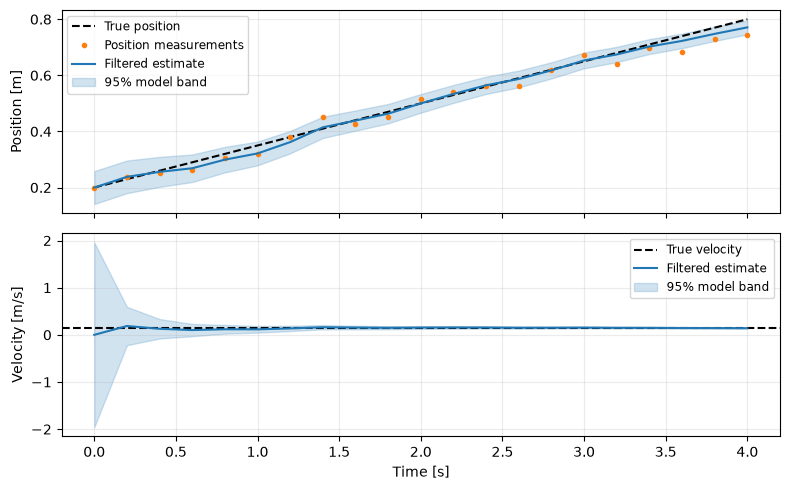

In [4]:
import matplotlib.pyplot as plt

demo_figure, demo_axes = plt.subplots(2, 1, figsize=(8, 5), sharex=True)
demo_axes[0].plot(demo_time, demo_true_position, "k--", label="True position")
demo_axes[0].plot(demo_time, demo_measurements, ".", color="C1", label="Position measurements")
demo_axes[0].set_ylabel("Position [m]")
demo_axes[1].axhline(demo_true_velocity, color="black", linestyle="--", label="True velocity")
demo_axes[1].set_ylabel("Velocity [m/s]")
for component, axis in enumerate(demo_axes):
    sigma = np.sqrt(demo_covariances[:, component, component])
    axis.plot(demo_time, demo_states[:, component], color="C0", label="Filtered estimate")
    axis.fill_between(demo_time, demo_states[:, component] - 1.96*sigma,
                      demo_states[:, component] + 1.96*sigma,
                      color="C0", alpha=0.2, label="95% model band")
    axis.legend(fontsize="small")
    axis.grid(alpha=0.25)
demo_axes[1].set_xlabel("Time [s]")
demo_figure.tight_layout()
plt.show()


Continue with [02 calibration](02_calibration.ipynb).